<a href="https://colab.research.google.com/github/maliboo-wow/ml-lab/blob/main/%D0%9B%D0%A03_%D0%91%D1%96%D0%B1%D1%96%D0%BA%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = "{:.4f}".format

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [6]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("house_price_regression_dataset.csv")

Saving house_price_regression_dataset.csv to house_price_regression_dataset (1).csv


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [7]:
import kagglehub

path = kagglehub.dataset_download("prokshitha/home-value-insights")
print("Папка з файлами:", path)
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "house_price_regression_dataset.csv"))

Using Colab cache for faster access to the 'home-value-insights' dataset.
Папка з файлами: /kaggle/input/home-value-insights
['house_price_regression_dataset.csv']


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [8]:
display(df.head())
df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.5996,0,5,262382.8523
1,4272,3,3,2016,4.7530,1,6,985260.8545
2,3592,1,2,2016,3.6348,0,9,777977.3901
3,966,1,2,1977,2.7307,1,8,229698.9187
4,4926,2,1,1993,4.6991,0,8,1041740.8589


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [9]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [10]:
df.isnull().sum()

,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [11]:
df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000
mean,2815.4220,2.9900,1.9730,1986.5500,2.7781,1.0220,5.6150,618861.0186
std,1255.5149,1.4276,0.8203,20.6329,1.2979,0.8150,2.8871,253568.0584
min,503.0000,1.0000,1.0000,1950.0000,0.5061,0.0000,1.0000,111626.8534
25%,1749.5000,2.0000,1.0000,1969.0000,1.6659,0.0000,3.0000,401648.2289
50%,2862.5000,3.0000,2.0000,1986.0000,2.8097,1.0000,6.0000,628267.2911
75%,3849.5000,4.0000,3.0000,2004.2500,3.9233,2.0000,8.0000,827141.2776
max,4999.0000,5.0000,3.0000,2022.0000,4.9893,2.0000,10.0000,1108236.8363


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [12]:
df["Neighborhood_Quality"].value_counts().sort_index()

,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

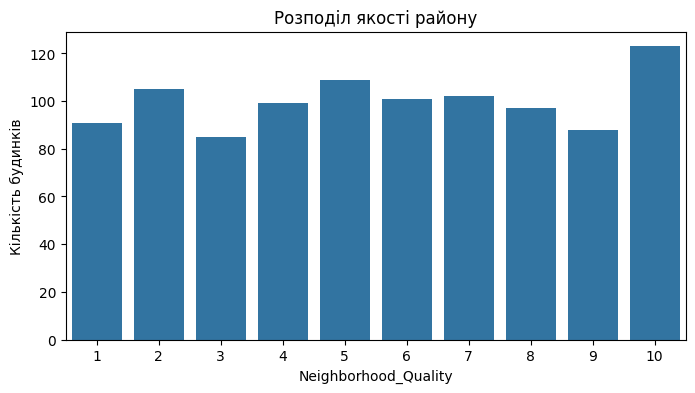

In [13]:
plt.figure(figsize=(8, 4))
sns.countplot(x="Neighborhood_Quality", data=df)
plt.title("Розподіл якості району")
plt.xlabel("Neighborhood_Quality")
plt.ylabel("Кількість будинків")
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [14]:
df["Num_Bathrooms"].value_counts().sort_index()

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

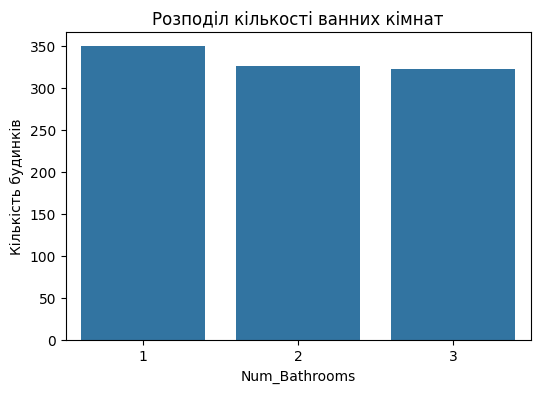

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Num_Bathrooms", data=df)
plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Num_Bathrooms")
plt.ylabel("Кількість будинків")
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

**Аналіз:** на графіках видно, що ціна майже по прямій лінії зростає разом із площею будинку (`Square_Footage`). Між ціною та іншими ознаками чіткої залежності не видно, точки розкидані хаотично.

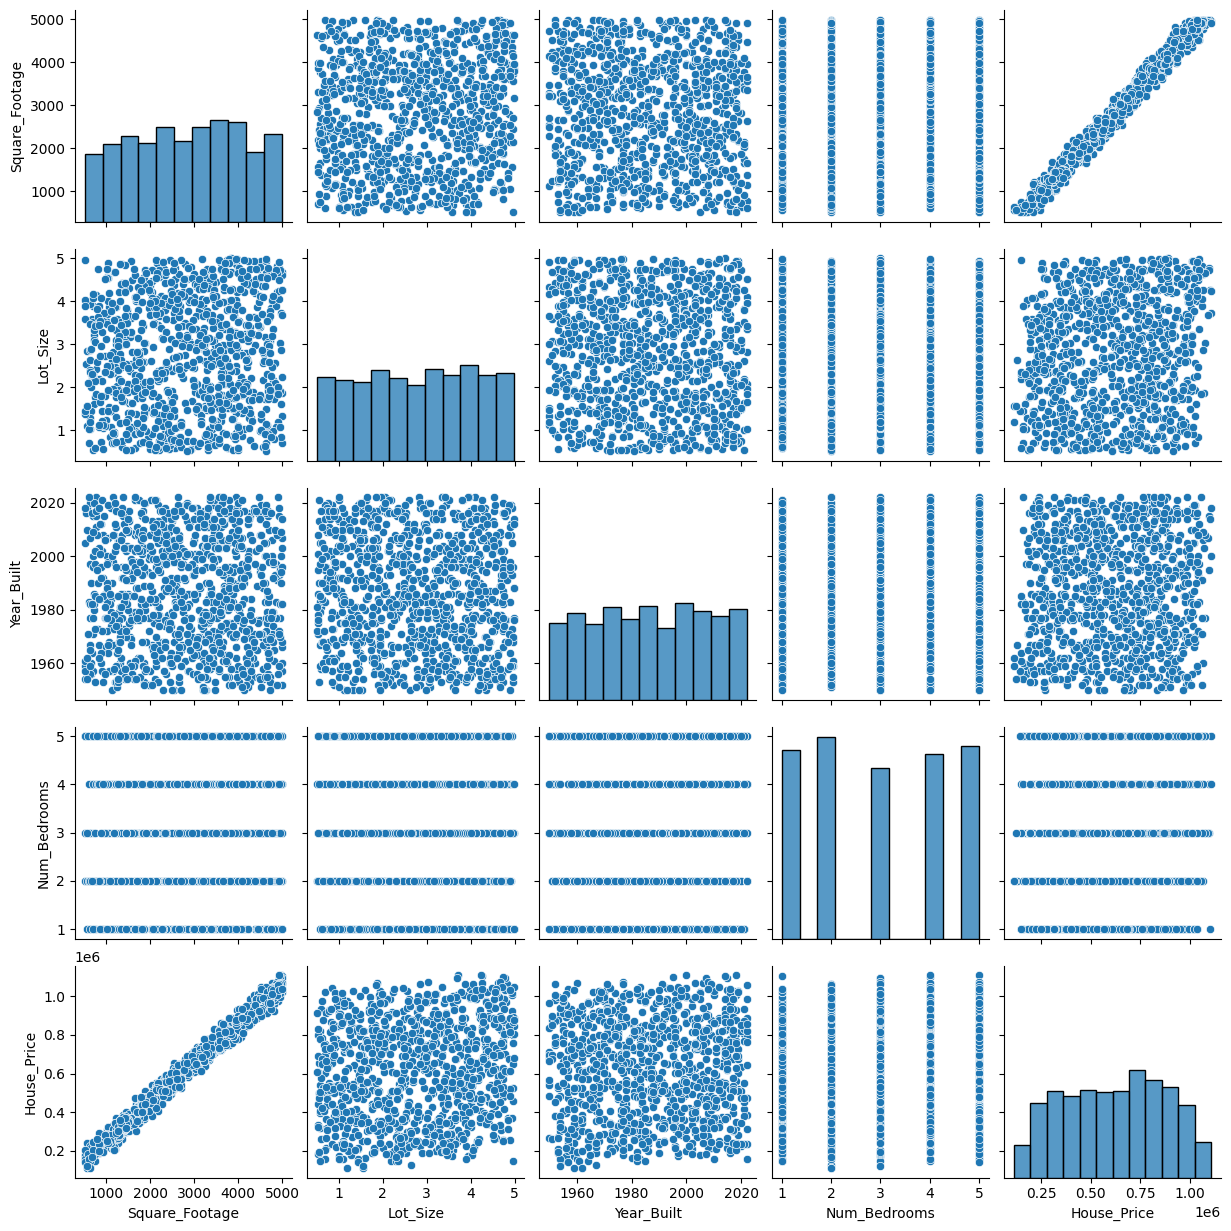

In [16]:
sns.pairplot(df[["Square_Footage", "Lot_Size", "Year_Built", "Num_Bedrooms", "House_Price"]])
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

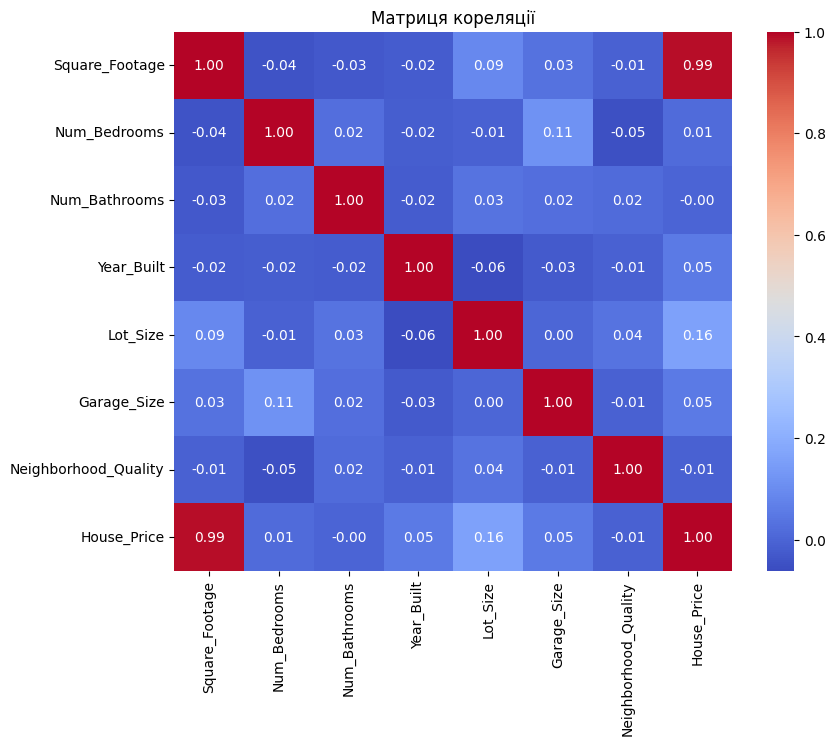

In [17]:
corr = df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Матриця кореляції")
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [18]:
corr["House_Price"].drop("House_Price").sort_values(ascending=False)

,House_Price
Square_Footage,0.9913
Lot_Size,0.1604
Garage_Size,0.0521
Year_Built,0.0520
Num_Bedrooms,0.0146
Num_Bathrooms,-0.0019
Neighborhood_Quality,-0.0078


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [19]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [20]:
X = df.drop("House_Price", axis=1)
y = df["House_Price"]

print(X.shape, y.shape)

(1000, 7) (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (800, 7)
Test: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [22]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=10000))
    ]),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [23]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Модель": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
results_df

,Модель,R2,MAE,MSE
0,Linear Regression,0.9984,8174.5836,101434798.5056
2,Lasso,0.9984,8174.7484,101436558.1801
1,Ridge,0.9984,8241.5869,102480990.0087
4,Gradient Boosting,0.9965,12305.2176,224965597.8451
3,Random Forest,0.9939,16114.2896,394131747.4460


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

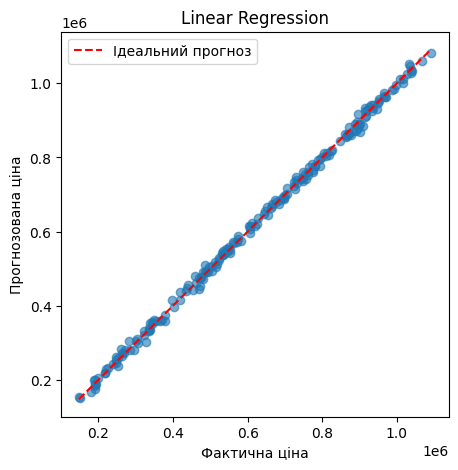

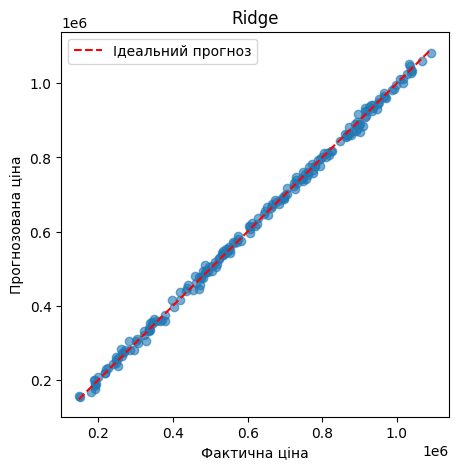

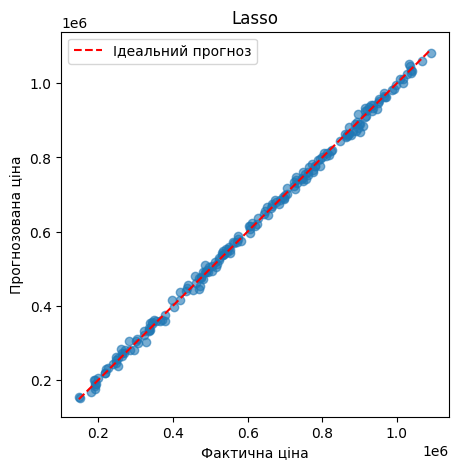

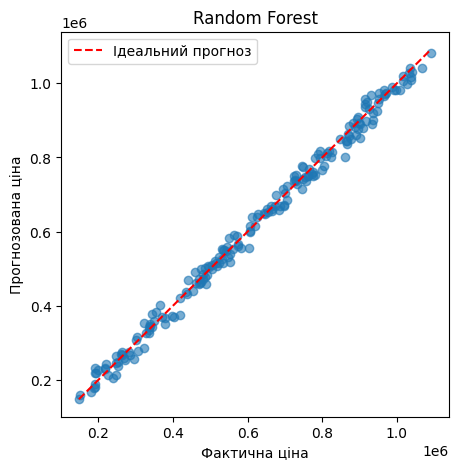

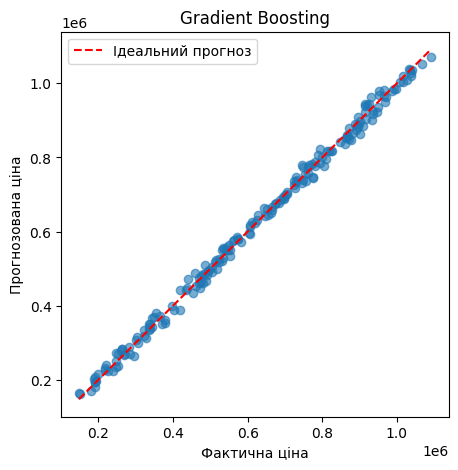

In [24]:
for name, y_pred in predictions.items():
    plt.figure(figsize=(5, 5))
    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Ідеальний прогноз")
    plt.title(name)
    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.legend()
    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [25]:
param_grid = {
    "n_estimators": [100, 200],
    "max_features": [1.0, "sqrt"],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("Найкращі параметри:", grid.best_params_)
print("Найкращий R2 на крос-валідації:", round(grid.best_score_, 4))

Найкращі параметри: {'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 200}
Найкращий R2 на крос-валідації: 0.992


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [26]:
best_rf = RandomForestRegressor(**grid.best_params_, random_state=42)
best_rf.fit(X_train, y_train)
y_pred_best = best_rf.predict(X_test)

print("R2: ", round(r2_score(y_test, y_pred_best), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred_best), 2))
print("MSE:", round(mean_squared_error(y_test, y_pred_best), 2))

R2:  0.994
MAE: 16035.17
MSE: 387229091.92


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [27]:
y_pred_rf = predictions["Random Forest"]

compare = pd.DataFrame({
    "Метрика": ["R2", "MAE", "MSE"],
    "Базовий RF": [
        r2_score(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_rf),
        mean_squared_error(y_test, y_pred_rf)
    ],
    "Оптимізований RF": [
        r2_score(y_test, y_pred_best),
        mean_absolute_error(y_test, y_pred_best),
        mean_squared_error(y_test, y_pred_best)
    ]
})
compare

,Метрика,Базовий RF,Оптимізований RF
0,R2,0.9939,0.9940
1,MAE,16114.2896,16035.1681
2,MSE,394131747.4460,387229091.9214


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

- Після підбору параметрів якість Random Forest покращилася зовсім трохи. Найкращі параметри: `n_estimators=200`, `max_depth=10`, `max_features=1.0`, `min_samples_split=2`.
- R² зріс з 0,99388 до 0,99393, MAE зменшилася з 16 130 до 16 057, MSE зменшилася з 3,945·10⁸ до 3,913·10⁸. Тобто змінилися всі три метрики, але різниця дуже мала.
- Оптимізовану модель використовувати можна, бо вона трохи точніша. Але великого виграшу вона не дає, і вона все одно гірша за лінійну регресію на цих даних.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [28]:
lr_table = pd.DataFrame({
    "Фактична ціна": y_test,
    "Прогнозована ціна": predictions["Linear Regression"]
})
lr_table["Похибка, %"] = abs(lr_table["Фактична ціна"] - lr_table["Прогнозована ціна"]) / lr_table["Фактична ціна"] * 100

print("Середня похибка, %:", round(lr_table["Похибка, %"].mean(), 2))
lr_table.sample(10, random_state=42).round(2)

Середня похибка, %: 1.66


,Фактична ціна,Прогнозована ціна,"Похибка, %"
436,1068538.1100,1059729.0200,0.8200
899,194353.7400,187868.5500,3.3400
346,270230.6400,279715.8200,3.5100
60,986006.8600,981949.2700,0.4100
867,953339.7300,957382.9500,0.4200
432,914555.7500,909764.2700,0.5200
543,746167.7300,742469.1400,0.5000
361,646766.2900,654445.5500,1.1900
486,523323.0700,524605.4400,0.2500
277,1008539.1600,1011343.6400,0.2800


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

1. Я побудувала п'ять моделей регресії: Linear Regression, Ridge, Lasso (усі три зі `StandardScaler` у `Pipeline`), Random Forest та Gradient Boosting. Також окремо підібрала параметри для Random Forest через GridSearchCV.
2. Найкращі метрики показала Linear Regression: R² = 0,9984, MAE ≈ 8 175. Lasso дала майже такий самий результат, Ridge трохи гірший. Деревоподібні моделі виявилися слабшими: Gradient Boosting R² = 0,9965, Random Forest R² = 0,9939.
3. Підбір гіперпараметрів майже не вплинув на Random Forest: R² зріс менше ніж на 0,0001, а MAE зменшилася приблизно на 73. Тобто базові параметри вже були нормальні.
4. Прогнози дуже точні. Для лінійної регресії середня похибка на тестовій вибірці приблизно 1,7%, у більшості випадків похибка менше 1%.
5. Найбільше на ціну впливає площа будинку: кореляція з ціною 0,99. Трохи впливає розмір ділянки (0,16), інші ознаки майже не пов'язані з ціною. Оскільки залежність майже лінійна, лінійні моделі тут працюють краще за дерева. На якість прогнозу також можуть впливати розмір вибірки (лише 1000 будинків), викиди та фактори, яких немає в датасеті, наприклад розташування чи стан будинку. Схоже, що датасет навчальний (згенерований), тому в реальних даних точність буде нижчою.